# **Breast Cancer Classification Using Machine Learning**

**Implementasi Machine Learning Menggunakan Python dan Google Colab**

Klasifikasi kanker payudara dilakukan dengan membangun model *Machine Learning* menggunakan algoritma Logistic Regression dan Random Forest Classifier. Dataset yang digunakan adalah *Breast Cancer Wisconsin Dataset* yang tersedia pada Scikit-learn. Dataset ini terdiri atas 569 sampel dengan 30 fitur numerik yang menggambarkan karakteristik sel tumor.

Model dibangun untuk mengklasifikasikan tumor ke dalam dua kategori:

*   Malignant (0): Tumor ganas.
*   Benign (1): Tumor jinak.

Proses implementasi dilakukan menggunakan Google Colab.

# **Step 1: Import Libraries**

Tahap pertama adalah mengimpor library Python yang diperlukan untuk proses pengolahan data, visualisasi, pembangunan model Machine Learning, dan evaluasi performa model.

In [4]:
# Library untuk pengolahan data numerik
import numpy as np
import pandas as pd

# Library untuk visualisasi data
import matplotlib.pyplot as plt
import seaborn as sns

# Mengambil dataset Breast Cancer dari Scikit-learn
from sklearn.datasets import load_breast_cancer

# Library untuk membagi dataset dan normalisasi data
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Library untuk membangun pipeline dan model klasifikasi
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

# Library untuk evaluasi performa model
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score
)

print("Semua library berhasil diimpor!")

Semua library berhasil diimpor!


# **Step 2: Load Dataset**

Pada tahap ini, memuat Breast Cancer Wisconsin Dataset menggunakan fungsi load_breast_cancer() dari Scikit-learn.

Dataset kemudian dikonversi menjadi DataFrame menggunakan Pandas agar lebih mudah dianalisis.

In [5]:
# Memuat Breast Cancer Wisconsin Dataset
data = load_breast_cancer()

# Mengambil fitur dan mengubahnya menjadi DataFrame
X = pd.DataFrame(
    data.data,
    columns=data.feature_names
)

# Mengambil label atau target kelas
y = data.target

# Menampilkan dimensi dataset
print("Dataset Shape:", X.shape)

# Menampilkan lima sampel pertama
print("\nFirst 5 Samples:")
print(X.head())

# Menampilkan nama kelas target
print("\nTarget Classes:")
print(data.target_names)

Dataset Shape: (569, 30)

First 5 Samples:
   mean radius  mean texture  mean perimeter  mean area  mean smoothness  \
0        17.99         10.38          122.80     1001.0          0.11840   
1        20.57         17.77          132.90     1326.0          0.08474   
2        19.69         21.25          130.00     1203.0          0.10960   
3        11.42         20.38           77.58      386.1          0.14250   
4        20.29         14.34          135.10     1297.0          0.10030   

   mean compactness  mean concavity  mean concave points  mean symmetry  \
0           0.27760          0.3001              0.14710         0.2419   
1           0.07864          0.0869              0.07017         0.1812   
2           0.15990          0.1974              0.12790         0.2069   
3           0.28390          0.2414              0.10520         0.2597   
4           0.13280          0.1980              0.10430         0.1809   

   mean fractal dimension  ...  worst radius  wor

Penjelasan:

*   data.data berisi data numerik yang digunakan sebagai fitur masukan.
*   data.feature_names berisi nama dari masing-masing fitur.
*   data.target berisi label atau kategori tumor.
*   X merupakan variabel yang menyimpan fitur.
*   y merupakan variabel yang menyimpan target klasifikasi.

# **Step 3: Exploratory Data Analysis (EDA)**

*Exploratory Data Analysis* (EDA) dilakukan untuk mengenali karakteristik dataset sebelum digunakan dalam pelatihan model *Machine Learning*. Pada tahap ini, dilakukan pemeriksaan terhadap beberapa aspek data, meliputi:

*   Jumlah sampel pada setiap kelas.
*   Distribusi data.
*   Nilai yang hilang (missing values).
*   Karakteristik fitur yang digunakan.

In [6]:
# Menampilkan informasi umum dataset
print("Dataset Information:")
print(X.info())

# Memeriksa jumlah missing values
print("\nMissing Values:")
print(X.isnull().sum().sum())

# Menampilkan statistik deskriptif
print("\nStatistical Description:")
print(X.describe())

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 30 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   mean radius              569 non-null    float64
 1   mean texture             569 non-null    float64
 2   mean perimeter           569 non-null    float64
 3   mean area                569 non-null    float64
 4   mean smoothness          569 non-null    float64
 5   mean compactness         569 non-null    float64
 6   mean concavity           569 non-null    float64
 7   mean concave points      569 non-null    float64
 8   mean symmetry            569 non-null    float64
 9   mean fractal dimension   569 non-null    float64
 10  radius error             569 non-null    float64
 11  texture error            569 non-null    float64
 12  perimeter error          569 non-null    float64
 13  area error               569 non-null    float64
 14  smoot

Penjelasan:

*   info() menampilkan informasi tipe data dan jumlah data pada setiap fitur.
*   isnull().sum().sum() menghitung total nilai yang hilang.
*   describe() menampilkan statistik deskriptif seperti mean, standar deviasi, minimum, dan maksimum.

**Check Class Distribution**

Distribusi jumlah sampel pada masing-masing kelas tumor diperiksa untuk mengetahui perbandingan jumlah data sampel untuk masing-masing kelas tumor.

Class Distribution:
0    212
1    357
Name: count, dtype: int64


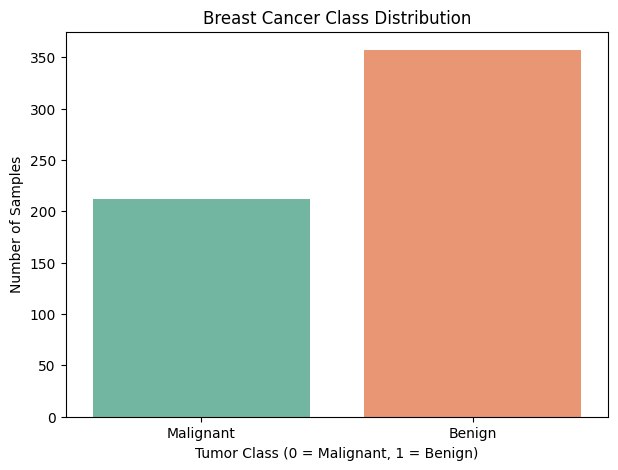

In [7]:
# Menghitung jumlah sampel pada setiap kelas
class_counts = pd.Series(y).value_counts().sort_index()

# Menampilkan jumlah sampel
print("Class Distribution:")
print(class_counts)

# Visualisasi distribusi kelas
plt.figure(figsize=(7, 5))

sns.countplot(
    x=y,
    hue=y,
    palette="Set2",
    legend=False
)

plt.title("Breast Cancer Class Distribution")
plt.xlabel("Tumor Class (0 = Malignant, 1 = Benign)")
plt.ylabel("Number of Samples")
plt.xticks([0, 1], ["Malignant", "Benign"])

plt.show()

Penjelasan:

Visualisasi ini digunakan untuk mengetahui jumlah sampel pada masing-masing kategori.

Informasi distribusi kelas penting karena ketidakseimbangan jumlah sampel dapat memengaruhi proses pelatihan dan evaluasi model.

# **Step 4: Dataset Splitting**

Sebelum membangun model Machine Learning, dataset perlu dibagi menjadi dua bagian:

*   Training Data: Data yang digunakan untuk melatih model.
*   Testing Data: Data yang digunakan untuk menguji kemampuan model terhadap data yang tidak digunakan selama pelatihan.

Pembagian dataset dapat dilakukan sebagai berikut:

*   70% Training Data.
*   30% Testing Data.

In [8]:
# Membagi dataset menjadi data training (70%) dan testing (30%)
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.3,
    random_state=42,
    stratify=y
)

# Menampilkan jumlah data training dan testing
print("Jumlah data training:", X_train.shape[0])
print("Jumlah data testing:", X_test.shape[0])

Jumlah data training: 398
Jumlah data testing: 171


Penjelasan parameter:

X: Dataset fitur

y: Label target

test_size=0.3:30% data digunakan untuk pengujian

random_state=42: Menjaga konsistensi pembagian data

stratify=y: Mempertahankan proporsi kelas pada training dan testing

# **Step 5: Data Normalization (Feature Scaling)**

Fitur dalam dataset memiliki rentang nilai yang berbeda.

Sebagai contoh:

- Mean Radius memiliki rentang nilai tertentu.
- Mean Area memiliki rentang nilai yang jauh lebih besar.
- Mean Smoothness memiliki rentang nilai yang relatif kecil.

Perbedaan skala tersebut dapat memengaruhi proses optimasi algoritma Machine Learning seperti Logistic Regression.

Oleh karena itu, kita menggunakan StandardScaler untuk melakukan standardisasi fitur.

Standardisasi dilakukan menggunakan persamaan:

$$
z = \frac{x - \mu}{\sigma}
$$

Keterangan:

- $x$ = Nilai fitur awal.
- $\mu$ = Rata-rata fitur.
- $\sigma$ = Standar deviasi fitur.
- $z$ = Nilai fitur setelah standardisasi.

Dalam implementasi ini, StandardScaler akan dimasukkan ke dalam Pipeline agar proses standardisasi dilakukan secara otomatis.

Catatan: StandardScaler hanya mempelajari parameter dari data training. Data testing hanya ditransformasikan menggunakan parameter tersebut untuk mencegah data leakage.

In [9]:
# Membuat pipeline Logistic Regression dengan standardisasi
model_lr = make_pipeline(
    StandardScaler(),
    LogisticRegression(
        max_iter=1000,
        random_state=42
    )
)

# Membuat model Random Forest
model_rf = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

# Melatih model Logistic Regression
model_lr.fit(X_train, y_train)

# Melatih model Random Forest
model_rf.fit(X_train, y_train)

print("Model Training Completed!")

Model Training Completed!


Penjelasan:

- StandardScaler() melakukan standardisasi fitur.
- LogisticRegression() membangun model klasifikasi.
- max_iter=1000 menentukan jumlah maksimum iterasi optimasi.
- n_estimators=100 menentukan jumlah pohon keputusan (decision trees) yang digunakan dalam Random Forest.
- fit() digunakan untuk melatih model berdasarkan data training.
- random_state=42 menjaga proses pengacakan agar hasil pelatihan lebih konsisten ketika kode dijalankan ulang.

Dengan menggunakan Pipeline, proses standardisasi dan pelatihan model dapat dilakukan dalam satu alur.

# **Step 6: Model Prediction**

Setelah model berhasil dilatih, langkah berikutnya adalah melakukan prediksi menggunakan data testing.

Model akan menghasilkan prediksi kategori tumor berdasarkan karakteristik fitur yang diberikan.

In [10]:
# Melakukan prediksi menggunakan data testing
y_pred_lr = model_lr.predict(X_test)
y_pred_rf = model_rf.predict(X_test)

# Menampilkan hasil prediksi Logistic Regression
print("Predicted Classes - Logistic Regression:")
print(y_pred_lr)

# Menampilkan hasil prediksi Random Forest
print("\nPredicted Classes - Random Forest:")
print(y_pred_rf)

# Menampilkan label sebenarnya
print("\nActual Classes:")
print(y_test)

Predicted Classes - Logistic Regression:
[0 1 1 0 0 0 1 0 1 0 1 1 0 1 1 0 0 1 1 1 1 1 1 0 0 1 1 1 0 0 1 0 1 1 0 1 1
 1 1 1 1 0 1 1 1 1 1 1 1 0 1 1 0 0 1 1 0 1 1 1 0 0 0 1 1 1 1 0 1 1 0 0 0 0
 1 1 1 1 0 1 1 1 0 1 0 1 1 0 0 0 0 1 1 1 1 1 0 1 0 1 1 1 1 0 1 1 1 1 0 1 0
 1 0 1 1 0 0 1 1 0 1 1 0 1 0 1 1 0 1 1 1 1 0 1 0 1 0 1 0 1 1 1 0 0 0 0 0 1
 0 1 1 1 0 1 0 1 1 0 1 1 0 0 1 1 0 1 1 1 1 0 1]

Predicted Classes - Random Forest:
[0 1 1 0 1 0 1 0 1 0 1 1 0 1 1 0 0 0 1 1 1 1 1 0 0 1 1 1 0 0 1 0 1 1 0 1 0
 1 1 1 1 0 1 1 1 1 1 1 1 0 1 1 0 0 1 1 0 1 1 1 0 0 0 1 1 1 1 0 1 1 0 0 0 0
 1 1 0 1 0 1 1 1 0 1 0 1 1 0 0 0 0 1 1 1 1 1 0 1 1 1 1 1 1 0 1 1 1 1 0 1 0
 1 0 1 1 0 1 1 1 0 1 1 0 1 1 1 1 0 1 1 1 1 0 1 0 1 0 1 1 1 1 1 0 0 0 0 0 1
 1 1 1 1 0 1 0 1 1 0 1 1 0 0 0 1 0 1 1 1 0 0 1]

Actual Classes:
[0 1 1 0 0 0 1 0 1 0 1 1 0 0 1 0 0 1 1 1 1 1 1 0 0 1 1 1 0 0 1 0 1 1 0 1 1
 1 1 1 1 0 1 1 1 1 1 1 1 0 1 1 0 0 1 1 0 1 1 1 0 0 0 1 1 1 1 0 1 1 0 0 0 0
 1 1 1 1 0 1 1 1 0 1 0 1 1 0 0 0 0 1 1 1 1 1 0 1 0 1 1 1 1 0

Penjelasan:

- predict() digunakan untuk menghasilkan prediksi kelas.
- y_pred_lr berisi hasil prediksi dari model Logistic Regression.
- y_pred_rf berisi hasil prediksi dari model Random Forest.
- y_test berisi kelas sebenarnya dari data testing.

Hasil prediksi kemudian dibandingkan dengan label sebenarnya untuk mengetahui tingkat ketepatan model.

# **Step 7: Model Evaluation**

Evaluasi dilakukan untuk mengukur dan membandingkan kemampuan model Logistic Regression dan Random Forest dalam mengklasifikasikan tumor dengan benar.

Pada Mini Assignment ini, digunakan beberapa metrik evaluasi:
- Accuracy.
- Precision.
- Recall.
- F1-Score.
- ROC-AUC.

In [11]:
# Menghitung metrik evaluasi Logistic Regression
accuracy_lr = accuracy_score(y_test, y_pred_lr)
precision_lr = precision_score(y_test, y_pred_lr, average='weighted')
recall_lr = recall_score(y_test, y_pred_lr, average='weighted')
f1_lr = f1_score(y_test, y_pred_lr, average='weighted')

# Menghitung metrik evaluasi Random Forest
accuracy_rf = accuracy_score(y_test, y_pred_rf)
precision_rf = precision_score(y_test, y_pred_rf, average='weighted')
recall_rf = recall_score(y_test, y_pred_rf, average='weighted')
f1_rf = f1_score(y_test, y_pred_rf, average='weighted')

# Menampilkan hasil evaluasi
print("=== Logistic Regression ===")
print("Accuracy:", accuracy_lr)
print("Accuracy (%):", accuracy_lr * 100)
print("Precision:", precision_lr)
print("Recall:", recall_lr)
print("F1-Score:", f1_lr)

print("\n=== Random Forest ===")
print("Accuracy:", accuracy_rf)
print("Accuracy (%):", accuracy_rf * 100)
print("Precision:", precision_rf)
print("Recall:", recall_rf)
print("F1-Score:", f1_rf)

=== Logistic Regression ===
Accuracy: 0.9883040935672515
Accuracy (%): 98.83040935672514
Precision: 0.9883040935672515
Recall: 0.9883040935672515
F1-Score: 0.9883040935672515

=== Random Forest ===
Accuracy: 0.935672514619883
Accuracy (%): 93.56725146198829
Precision: 0.9355332776385409
Recall: 0.935672514619883
F1-Score: 0.9355688556066355


**Accuracy**

Accuracy menunjukkan persentase jumlah prediksi yang benar dibandingkan dengan keseluruhan jumlah data pengujian. Metrik ini digunakan untuk mengetahui seberapa tepat model Logistic Regression dan Random Forest dalam mengklasifikasikan tumor.

$$
Accuracy = \frac{TP+TN}{TP+TN+FP+FN}
$$

Keterangan:

- TP = True Positive.
- TN = True Negative.
- FP = False Positive.
- FN = False Negative.

In [13]:
# Menampilkan classification report Logistic Regression
print("=== Classification Report - Logistic Regression ===")
print(
    classification_report(
        y_test,
        y_pred_lr,
        target_names=data.target_names
    )
)

# Menampilkan classification report Random Forest
print("\n=== Classification Report - Random Forest ===")
print(
    classification_report(
        y_test,
        y_pred_rf,
        target_names=data.target_names
    )
)

=== Classification Report - Logistic Regression ===
              precision    recall  f1-score   support

   malignant       0.98      0.98      0.98        64
      benign       0.99      0.99      0.99       107

    accuracy                           0.99       171
   macro avg       0.99      0.99      0.99       171
weighted avg       0.99      0.99      0.99       171


=== Classification Report - Random Forest ===
              precision    recall  f1-score   support

   malignant       0.92      0.91      0.91        64
      benign       0.94      0.95      0.95       107

    accuracy                           0.94       171
   macro avg       0.93      0.93      0.93       171
weighted avg       0.94      0.94      0.94       171



**Precision, Recall, and F1-Score**

Ketiga metrik ini digunakan untuk memahami performa klasifikasi secara lebih detail.

- Precision: Mengukur ketepatan prediksi pada suatu kelas.
- Recall: Mengukur kemampuan model menemukan seluruh sampel dari suatu kelas.
- F1-Score: Harmonic mean antara precision dan recall.

In [14]:
# Mengambil probabilitas prediksi kelas 1 (Benign)
y_probability_lr = model_lr.predict_proba(X_test)[:, 1]
y_probability_rf = model_rf.predict_proba(X_test)[:, 1]

# Menghitung nilai ROC-AUC kedua model
auc_lr = roc_auc_score(y_test, y_probability_lr)
auc_rf = roc_auc_score(y_test, y_probability_rf)

# Menampilkan hasil ROC-AUC
print("\nROC-AUC Logistic Regression:", auc_lr)
print("ROC-AUC Random Forest:", auc_rf)


ROC-AUC Logistic Regression: 0.9981016355140186
ROC-AUC Random Forest: 0.991311331775701


**ROC-AUC**

ROC-AUC digunakan untuk mengukur kemampuan model dalam membedakan dua kelas berdasarkan berbagai nilai threshold.

Logistic Regression memperoleh nilai ROC-AUC sebesar 0,9981, sedangkan Random Forest sebesar 0,9913. Kedua model memiliki kemampuan diskriminasi yang sangat baik dalam membedakan kelas *malignant* (tumor ganas) dan *benign* (tumor jinak). Logistic Regression menunjukkan kemampuan diskriminasi yang sedikit lebih baik dibandingkan Random Forest karena memiliki nilai ROC-AUC yang lebih tinggi.

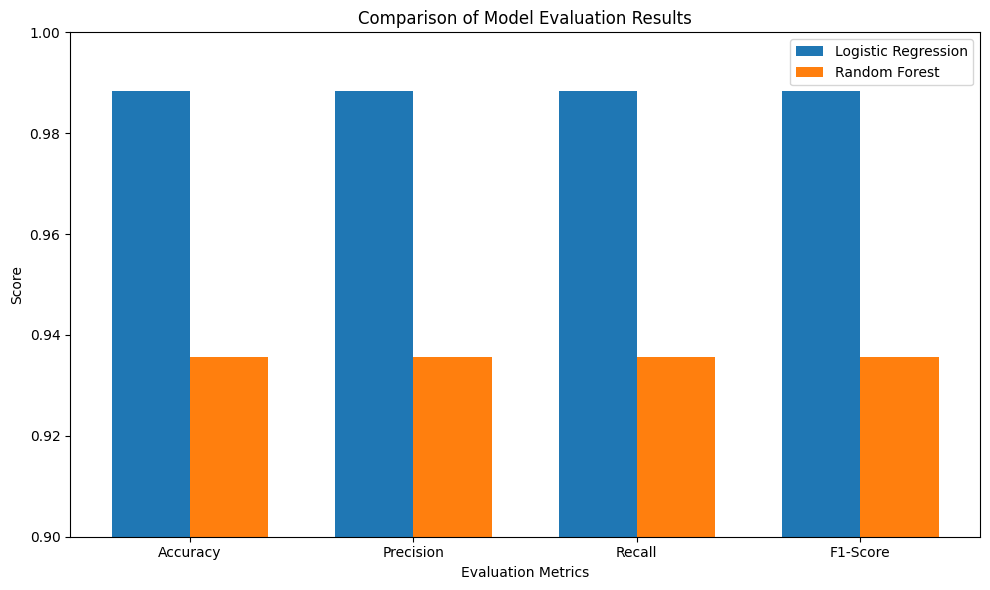

In [19]:
# Membuat grafik perbandingan hasil evaluasi

metrics = ['Accuracy', 'Precision', 'Recall', 'F1-Score']

lr_scores = [accuracy_lr, precision_lr, recall_lr, f1_lr]
rf_scores = [accuracy_rf, precision_rf, recall_rf, f1_rf]

x = np.arange(len(metrics))
width = 0.35

plt.figure(figsize=(10, 6))

plt.bar(x - width/2, lr_scores, width,
        label='Logistic Regression')

plt.bar(x + width/2, rf_scores, width,
        label='Random Forest')

plt.xlabel('Evaluation Metrics')
plt.ylabel('Score')
plt.title('Comparison of Model Evaluation Results')

plt.xticks(x, metrics)
plt.ylim(0.90, 1.00)

plt.legend()
plt.tight_layout()

plt.savefig('evaluation_results.png', dpi=300)
plt.show()

# **Step 8: Confusion Matrix**

Confusion Matrix merupakan tabel yang digunakan untuk membandingkan hasil prediksi model dengan kelas sebenarnya.

Confusion Matrix memiliki empat komponen utama:
| Komponen | Keterangan |
|:--|:--|
| True Positive (TP) | Sampel positif yang diprediksi positif |
| True Negative (TN) | Sampel negatif yang diprediksi negatif |
| False Positive (FP) | Sampel negatif yang diprediksi positif |
| False Negative (FN) | Sampel positif yang diprediksi negatif |

Pada dataset ini, kelas positif secara default adalah kelas 1 (Benign), sedangkan kelas negatif adalah kelas 0 (Malignant).

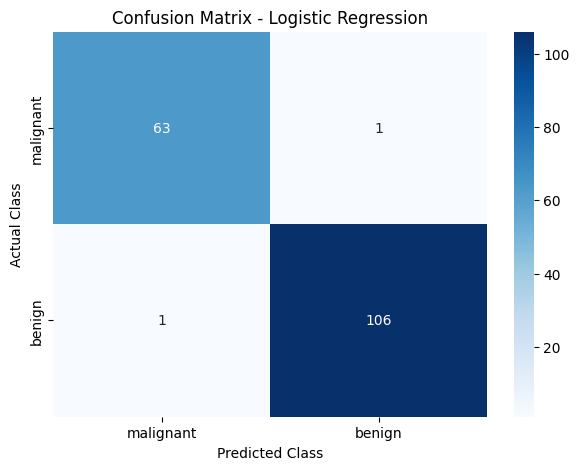

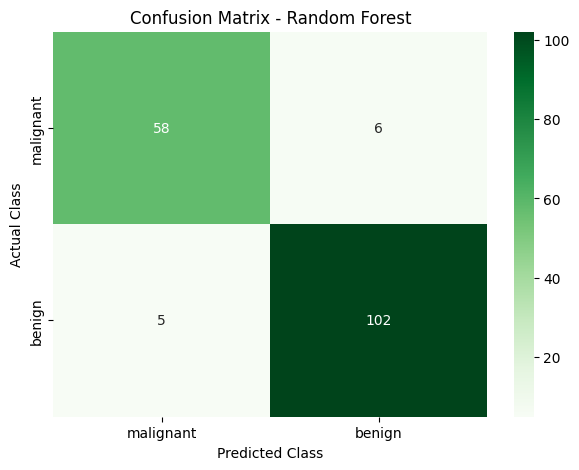

In [17]:
# Menghitung confusion matrix Logistic Regression
cm_lr = confusion_matrix(y_test, y_pred_lr)

# Visualisasi confusion matrix Logistic Regression
plt.figure(figsize=(7, 5))

sns.heatmap(
    cm_lr,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=data.target_names,
    yticklabels=data.target_names
)

plt.title("Confusion Matrix - Logistic Regression")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.show()


# Menghitung confusion matrix Random Forest
cm_rf = confusion_matrix(y_test, y_pred_rf)

# Visualisasi confusion matrix Random Forest
plt.figure(figsize=(7, 5))

sns.heatmap(
    cm_rf,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=data.target_names,
    yticklabels=data.target_names
)

plt.title("Confusion Matrix - Random Forest")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.show()

Interpretasi:

- Diagonal utama menunjukkan jumlah prediksi yang benar, sedangkan sel di luar diagonal menunjukkan jumlah kesalahan prediksi.
- Pada Logistic Regression, terdapat 63 sampel *malignant* dan 106 sampel *benign* yang berhasil diklasifikasikan dengan benar. Model melakukan kesalahan pada 2 sampel, yaitu 1 sampel *malignant* diprediksi sebagai *benign* dan 1 sampel *benign* diprediksi sebagai *malignant*.
- Pada Random Forest, terdapat 58 sampel *malignant* dan 102 sampel *benign* yang berhasil diklasifikasikan dengan benar. Model melakukan kesalahan pada 11 sampel, yaitu 6 sampel *malignant* diprediksi sebagai *benign* dan 5 sampel *benign* diprediksi sebagai *malignant*.

Kesalahan klasifikasi tumor *malignant* (ganas) sebagai *benign* (jinak) perlu mendapat perhatian khusus karena dapat menyebabkan tumor ganas tidak teridentifikasi. Logistic Regression memiliki jumlah kesalahan tersebut lebih sedikit, yaitu 1 sampel, dibandingkan Random Forest sebanyak 6 sampel.



# **Step 9: Predict a New Sample**

Pada tahap terakhir, kita akan mencoba menggunakan model yang telah dilatih untuk memprediksi satu sampel baru.

Sebagai contoh, kita mengambil satu sampel dari data testing.

In [16]:
# Mengambil satu sampel dari data testing
sample = X_test.iloc[[0]]

# Menampilkan fitur sampel
print("Input Sample:")
print(sample)

# Melakukan prediksi menggunakan Logistic Regression
prediction_lr = model_lr.predict(sample)[0]
probability_lr = model_lr.predict_proba(sample)[0]

# Melakukan prediksi menggunakan Random Forest
prediction_rf = model_rf.predict(sample)[0]
probability_rf = model_rf.predict_proba(sample)[0]

# Mengubah label numerik menjadi nama kelas
result_lr = data.target_names[prediction_lr]
result_rf = data.target_names[prediction_rf]

# Menampilkan hasil prediksi Logistic Regression
print("\n=== Logistic Regression ===")
print("Prediction Result:", result_lr)
print("Prediction Probability:")

for class_name, prob in zip(data.target_names, probability_lr):
    print(class_name, ":", round(prob * 100, 2), "%")

# Menampilkan hasil prediksi Random Forest
print("\n=== Random Forest ===")
print("Prediction Result:", result_rf)
print("Prediction Probability:")

for class_name, prob in zip(data.target_names, probability_rf):
    print(class_name, ":", round(prob * 100, 2), "%")

Input Sample:
    mean radius  mean texture  mean perimeter  mean area  mean smoothness  \
14        13.73         22.61            93.6      578.3           0.1131   

    mean compactness  mean concavity  mean concave points  mean symmetry  \
14            0.2293          0.2128              0.08025         0.2069   

    mean fractal dimension  ...  worst radius  worst texture  worst perimeter  \
14                 0.07682  ...         15.03          32.01            108.8   

    worst area  worst smoothness  worst compactness  worst concavity  \
14       697.7            0.1651             0.7725           0.6943   

    worst concave points  worst symmetry  worst fractal dimension  
14                0.2208          0.3596                   0.1431  

[1 rows x 30 columns]

=== Logistic Regression ===
Prediction Result: malignant
Prediction Probability:
malignant : 96.79 %
benign : 3.21 %

=== Random Forest ===
Prediction Result: malignant
Prediction Probability:
malignant : 92.0 

Penjelasan:

1. X_test.iloc[[0]] mengambil satu sampel dari data testing.
2. predict() menghasilkan kategori hasil klasifikasi.
3. predict_proba() menghasilkan probabilitas prediksi untuk masing-masing kelas.
4. data.target_names mengubah label numerik menjadi nama kategori.

Catatan: Model ini digunakan hanya untuk pembelajaran dan demonstrasi Machine Learning. Hasil prediksi tidak boleh digunakan sebagai pengganti diagnosis medis profesional.

## Kesimpulan

Klasifikasi kanker payudara menggunakan *Machine Learning* dilakukan dengan *Breast Cancer Wisconsin Dataset* yang terdiri atas 569 sampel dan 30 fitur numerik. Tahapan pengerjaan meliputi pemuatan dan eksplorasi data (EDA), pembagian dataset menjadi 70% data training dan 30% data testing, serta pembangunan model Logistic Regression dan Random Forest Classifier. Standardisasi fitur menggunakan *StandardScaler* diterapkan pada Logistic Regression.

Evaluasi dilakukan menggunakan Accuracy, Precision, Recall, F1-Score, ROC-AUC, dan *Confusion Matrix*. Logistic Regression memperoleh akurasi sebesar 98,83% dan ROC-AUC 0,9981, sedangkan Random Forest memperoleh akurasi 93,57% dan ROC-AUC 0,9913. Logistic Regression juga memiliki jumlah kesalahan klasifikasi lebih sedikit, yaitu 2 dibandingkan 11 pada Random Forest.

Secara keseluruhan, Logistic Regression menunjukkan performa klasifikasi lebih baik dibandingkan Random Forest pada dataset yang digunakan. Evaluasi berbagai metrik diperlukan untuk mengetahui kemampuan model secara menyeluruh, terutama dalam mengenali tumor ganas. Hal ini penting dalam bidang kesehatan karena kesalahan klasifikasi tumor ganas sebagai tumor jinak dapat berisiko apabila digunakan dalam konteks klinis. Meskipun demikian, hasil prediksi model tidak dapat menggantikan pemeriksaan dan diagnosis medis.